In [ ]:
https://www.kaggle.com/datasets/adityaakuskar/accident-prediction-dataset

# 1.Project Prediction
+ Our project predicts the severity of a road traffic accident as Slight Injury, Serious Injury, or Fatal Injury using the driver's information, vehicle details, road conditions, weather conditions, accident circumstances, and other related factors.

#### 1.1 Business Problems:
+ To analyze road traffic accident data and identify the factors associated with accident severity, such as driver characteristics, road conditions, weather, vehicle conditions, and accident circumstances.

# 2.Dataset Understanding

In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
import matplotlib.pyplot as plt

In [4]:
import seaborn as sns

In [5]:
df = pd.read_csv(r"C:\Users\mundr\Downloads\RTA Dataset.csv")
df.head(1)

,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,...,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
0,17:02:00,Monday,18-30,Male,Above high school,Employee,1-2yr,Automobile,Owner,Above 10yr,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Moving Backward,Slight Injury


In [6]:
df.shape

(12316, 32)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12316 entries, 0 to 12315
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Time                         12316 non-null  str  
 1   Day_of_week                  12316 non-null  str  
 2   Age_band_of_driver           12316 non-null  str  
 3   Sex_of_driver                12316 non-null  str  
 4   Educational_level            11575 non-null  str  
 5   Vehicle_driver_relation      11737 non-null  str  
 6   Driving_experience           11487 non-null  str  
 7   Type_of_vehicle              11366 non-null  str  
 8   Owner_of_vehicle             11834 non-null  str  
 9   Service_year_of_vehicle      8388 non-null   str  
 10  Defect_of_vehicle            7889 non-null   str  
 11  Area_accident_occured        12077 non-null  str  
 12  Lanes_or_Medians             11931 non-null  str  
 13  Road_allignment              12174 non-null  str  
 14  T

In [8]:
df.describe()

,Number_of_vehicles_involved,Number_of_casualties
count,12316.000000,12316.000000
mean,2.040679,1.548149
std,0.688790,1.007179
min,1.000000,1.000000
25%,2.000000,1.000000
50%,2.000000,1.000000
75%,2.000000,2.000000
max,7.000000,8.000000


In [9]:
df.columns

Index(['Time', 'Day_of_week', 'Age_band_of_driver', 'Sex_of_driver',
       'Educational_level', 'Vehicle_driver_relation', 'Driving_experience',
       'Type_of_vehicle', 'Owner_of_vehicle', 'Service_year_of_vehicle',
       'Defect_of_vehicle', 'Area_accident_occured', 'Lanes_or_Medians',
       'Road_allignment', 'Types_of_Junction', 'Road_surface_type',
       'Road_surface_conditions', 'Light_conditions', 'Weather_conditions',
       'Type_of_collision', 'Number_of_vehicles_involved',
       'Number_of_casualties', 'Vehicle_movement', 'Casualty_class',
       'Sex_of_casualty', 'Age_band_of_casualty', 'Casualty_severity',
       'Work_of_casuality', 'Fitness_of_casuality', 'Pedestrian_movement',
       'Cause_of_accident', 'Accident_severity'],
      dtype='str')

# 3.Data Cleaning

In [10]:
df.isnull().mean() * 100

Time                            0.000000
Day_of_week                     0.000000
Age_band_of_driver              0.000000
Sex_of_driver                   0.000000
Educational_level               6.016564
Vehicle_driver_relation         4.701202
Driving_experience              6.731082
Type_of_vehicle                 7.713543
Owner_of_vehicle                3.913608
Service_year_of_vehicle        31.893472
Defect_of_vehicle              35.945112
Area_accident_occured           1.940565
Lanes_or_Medians                3.126015
Road_allignment                 1.152972
Types_of_Junction               7.202014
Road_surface_type               1.396557
Road_surface_conditions         0.000000
Light_conditions                0.000000
Weather_conditions              0.000000
Type_of_collision               1.258525
Number_of_vehicles_involved     0.000000
Number_of_casualties            0.000000
Vehicle_movement                2.500812
Casualty_class                  0.000000
Sex_of_casualty 

In [11]:
num = df.select_dtypes(include = ["int64","float64"]).columns
num

Index(['Number_of_vehicles_involved', 'Number_of_casualties'], dtype='str')

In [12]:
import warnings
warnings.filterwarnings("ignore")

In [13]:
cat =  df.select_dtypes(include="object").columns
cat

Index(['Time', 'Day_of_week', 'Age_band_of_driver', 'Sex_of_driver',
       'Educational_level', 'Vehicle_driver_relation', 'Driving_experience',
       'Type_of_vehicle', 'Owner_of_vehicle', 'Service_year_of_vehicle',
       'Defect_of_vehicle', 'Area_accident_occured', 'Lanes_or_Medians',
       'Road_allignment', 'Types_of_Junction', 'Road_surface_type',
       'Road_surface_conditions', 'Light_conditions', 'Weather_conditions',
       'Type_of_collision', 'Vehicle_movement', 'Casualty_class',
       'Sex_of_casualty', 'Age_band_of_casualty', 'Casualty_severity',
       'Work_of_casuality', 'Fitness_of_casuality', 'Pedestrian_movement',
       'Cause_of_accident', 'Accident_severity'],
      dtype='str')

In [14]:
for i in num:
    df[i] = df[i].fillna(df[i].median())

In [15]:
for j in cat:
    df[j] = df[j].fillna(df[j].mode()[0])

In [16]:
df.isnull().mean() * 100

Time                           0.0
Day_of_week                    0.0
Age_band_of_driver             0.0
Sex_of_driver                  0.0
Educational_level              0.0
Vehicle_driver_relation        0.0
Driving_experience             0.0
Type_of_vehicle                0.0
Owner_of_vehicle               0.0
Service_year_of_vehicle        0.0
Defect_of_vehicle              0.0
Area_accident_occured          0.0
Lanes_or_Medians               0.0
Road_allignment                0.0
Types_of_Junction              0.0
Road_surface_type              0.0
Road_surface_conditions        0.0
Light_conditions               0.0
Weather_conditions             0.0
Type_of_collision              0.0
Number_of_vehicles_involved    0.0
Number_of_casualties           0.0
Vehicle_movement               0.0
Casualty_class                 0.0
Sex_of_casualty                0.0
Age_band_of_casualty           0.0
Casualty_severity              0.0
Work_of_casuality              0.0
Fitness_of_casuality

# 4.Checking Outliers for numerical columns

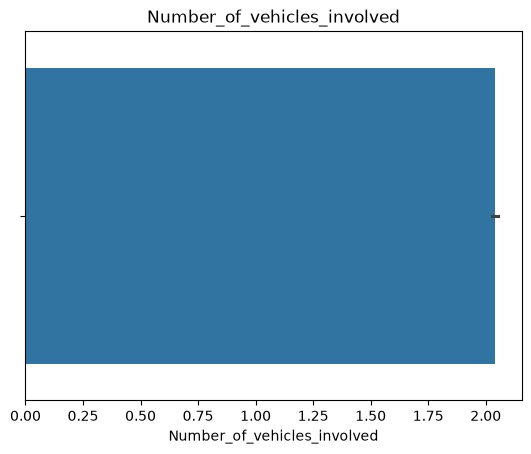

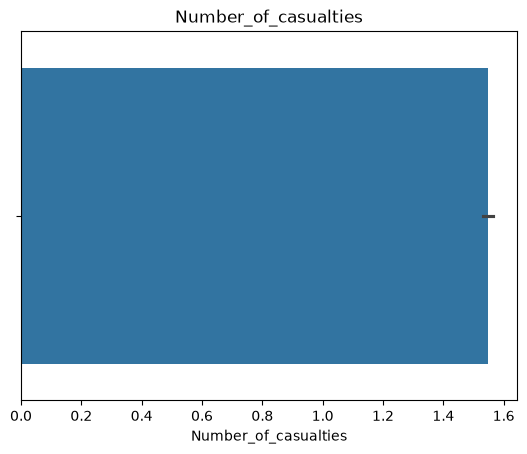

In [17]:
for i in num:
    sns.barplot(data = df , x = i)
    plt.title(i)
    plt.show(i)

In [18]:
def outlier(df , columns):
    q1 = df[i].quantile(0.25)
    q3 = df[i].quantile(0.75)

    iqr = q3 -  q1 

    lb = q1 - 1.5 * iqr
    ub = q3 + 1.5 * iqr

    return df[(df[i] < lb) | (df[i] > ub)]

In [19]:
for i in num:
    print("\n",i)
    print(len(outlier(df,i)))


 Number_of_vehicles_involved
3976

 Number_of_casualties
720


# 5.Treatment of outlier

In [20]:
from feature_engine.outliers import Winsorizer

In [21]:
win_obj = Winsorizer(capping_method= "iqr",tail="both")
win_obj

,capping_method,'iqr'
,tail,'both'
,fold,'auto'
,add_indicators,False
,variables,None
,missing_values,'raise'


In [22]:
win = Winsorizer(
    capping_method="iqr",
    tail="both",
    fold=1.5,
    variables=["Number_of_casualties"])

df[["Number_of_casualties"]] = win.fit_transform(df[["Number_of_casualties"]])

In [23]:
for i in num:
    print("\n",i)
    print(len(outlier(df,i)))


 Number_of_vehicles_involved
3976

 Number_of_casualties
0


# 6. checking for duplicates

In [24]:
df.duplicated().sum()

np.int64(0)

# 7.checking data inconsistent ot not

#### 7.1 checking for Numerical Columns

In [25]:
for i in num:
    print("\n",i)
    print(df[i].unique())


 Number_of_vehicles_involved
[2 1 3 6 4 7]

 Number_of_casualties
[2.  1.  3.  3.5]


#### 
7.2 Converting Float to Int

In [26]:
df["Number_of_casualties"] = df["Number_of_casualties"].astype(int)

In [27]:
df[['Number_of_vehicles_involved','Number_of_casualties']].dtypes

Number_of_vehicles_involved    int64
Number_of_casualties           int64
dtype: object

#### 
7.3  checking for  Categorical Columns

In [28]:
for j in cat:
    print("\n",j)
    print(df[j].unique())


 Time
<StringArray>
['17:02:00', '01:06:00', '14:15:00', '17:30:00', '17:20:00', '14:40:00',
 '17:45:00', '22:45:00', '08:20:00', '15:10:00',
 ...
 '23:55:00', '15:58:00', '10:26:00', '05:53:00', '08:34:00', '22:11:00',
 '07:02:00', '07:24:00', '19:18:00', '02:47:00']
Length: 1074, dtype: str

 Day_of_week
<StringArray>
['Monday', 'Sunday', 'Friday', 'Wednesday', 'Saturday', 'Thursday', 'Tuesday']
Length: 7, dtype: str

 Age_band_of_driver
<StringArray>
['18-30', '31-50', 'Under 18', 'Over 51', 'Unknown']
Length: 5, dtype: str

 Sex_of_driver
<StringArray>
['Male', 'Female', 'Unknown']
Length: 3, dtype: str

 Educational_level
<StringArray>
[ 'Above high school', 'Junior high school',  'Elementary school',
        'High school',            'Unknown',         'Illiterate',
  'Writing & reading']
Length: 7, dtype: str

 Vehicle_driver_relation
<StringArray>
['Employee', 'Unknown', 'Owner', 'Other']
Length: 4, dtype: str

 Driving_experience
<StringArray>
['1-2yr', 'Above 10yr', '5-10yr'

#### 7.3.1 Remove leading/trailing spaces from all text columns

In [29]:
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

#### 7.3.2 Replace multiple spaces with a single space

In [30]:
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.replace(r"\s+", " ", regex=True)

#### 7.3.3 Fix capitalization inconsistencies

In [31]:
df["Driving_experience"] = df["Driving_experience"].replace({"unknown": "Unknown"})
df["Lanes_or_Medians"] = df["Lanes_or_Medians"].replace({"other": "Other"})

#### 7.3.4 Fix Area_accident_occured

In [32]:
df["Area_accident_occured"] = df["Area_accident_occured"].replace({
    "Rural village areasOffice areas": "Rural village areas",
    "  Recreational areas": "Recreational areas",
    " Industrial areas": "Industrial areas",
    " Church areas": "Church areas",
    "  Market areas": "Market areas",
    " Outside rural areas": "Outside rural areas",
    " Hospital areas": "Hospital areas"})

#### 7.3.5 Fix Type_of_vehicle

In [33]:
df["Type_of_vehicle"] = df["Type_of_vehicle"].replace({
    "Lorry (41?100Q)": "Lorry (41-100Q)",
    "Lorry (11?40Q)": "Lorry (11-40Q)",
    "Public (13?45 seats)": "Public (13-45 seats)"})

#### 7.3.6 Fix Pedestrian_movement

In [34]:
df["Pedestrian_movement"] = df["Pedestrian_movement"].replace({
    "statioNot a Pedestrianry vehicle": "Not a Pedestrian",
    "parked or statioNot a Pedestrianry vehicle": "Not a Pedestrian"})

#### 7.3.7 Fix Fitness_of_casuality

In [35]:
df["Fitness_of_casuality"] = df["Fitness_of_casuality"].replace({
    "NormalNormal": "Normal"})

#### 7.3.8 Check for remaining special symbols

In [36]:
for col in df.select_dtypes(include="object").columns:
    special = df[col].astype(str).str.contains(
        r"[^A-Za-z0-9\s&()/.,+_\-]",
        regex=True)

# 8. Data Manipulation

### 1. Find the average number of casualties for each accident severity?

In [37]:
df.groupby('Accident_severity')[['Number_of_vehicles_involved','Number_of_casualties']].mean()

,Number_of_vehicles_involved,Number_of_casualties
Accident_severity,,
Fatal injury,1.797468,1.987342
Serious Injury,1.895009,1.425703
Slight Injury,2.068747,1.446471


### 2. Find the average number of vehicles involved for each accident severity?

In [38]:
df.groupby("Accident_severity")["Number_of_vehicles_involved"].mean()

Accident_severity
Fatal injury      1.797468
Serious Injury    1.895009
Slight Injury     2.068747
Name: Number_of_vehicles_involved, dtype: float64

### 3. Find all accidents involving more than 3 vehicles and more than 2 casualties.

In [40]:
df.query('Number_of_vehicles_involved > 3 and Number_of_casualties > 2')

,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,...,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
454,11:30:00,Tuesday,18-30,Male,Junior high school,Employee,1-2yr,Lorry (41-100Q),Owner,Unknown,...,Going straight,na,na,na,na,Driver,Normal,Not a Pedestrian,Changing lane to the left,Serious Injury
455,11:30:00,Tuesday,18-30,Male,Junior high school,Employee,1-2yr,Lorry (41-100Q),Owner,Unknown,...,Going straight,Passenger,Female,18-30,3,Driver,Normal,Not a Pedestrian,No distancing,Serious Injury
456,11:30:00,Tuesday,Under 18,Male,High school,Employee,2-5yr,Automobile,Organization,5-10yrs,...,Going straight,Driver or rider,Male,31-50,3,Driver,Normal,Not a Pedestrian,No priority to vehicle,Serious Injury
457,11:30:00,Tuesday,Under 18,Male,Junior high school,Employee,2-5yr,Automobile,Organization,2-5yrs,...,Reversing,Pedestrian,Male,18-30,3,Self-employed,Normal,Crossing from offside - masked by parked or st...,Changing lane to the right,Serious Injury
458,11:30:00,Tuesday,Under 18,Male,Junior high school,Employee,1-2yr,Public (13-45 seats),Owner,Unknown,...,Going straight,Driver or rider,Male,Over 51,2,Driver,Normal,Not a Pedestrian,No distancing,Serious Injury
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12107,16:05:00,Tuesday,Over 51,Male,Junior high school,Employee,Below 1yr,Automobile,Owner,Unknown,...,Going straight,Passenger,Female,18-30,3,Driver,Normal,Not a Pedestrian,No distancing,Slight Injury
12108,22:05:00,Friday,18-30,Male,Junior high school,Employee,1-2yr,Automobile,Owner,5-10yrs,...,Going straight,Driver or rider,Male,18-30,3,Self-employed,Normal,Not a Pedestrian,No distancing,Slight Injury
12109,22:05:00,Friday,18-30,Male,Elementary school,Employee,2-5yr,Other,Owner,Unknown,...,Going straight,na,na,na,na,Self-employed,Normal,Not a Pedestrian,Changing lane to the left,Slight Injury
12110,22:05:00,Friday,18-30,Male,Elementary school,Employee,2-5yr,Stationwagen,Owner,Unknown,...,Going straight,Driver or rider,Male,18-30,3,Driver,Normal,Not a Pedestrian,Changing lane to the right,Slight Injury


### 4. Find accidents involving more than 2 vehicles and more than 2 casualties?

In [41]:
df.query('Number_of_vehicles_involved > 2 and Number_of_casualties > 2').iloc[0:10]

,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,...,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
360,16:55:00,Friday,31-50,Male,Junior high school,Employee,Below 1yr,Automobile,Owner,1-2yr,...,Unknown,Pedestrian,Male,Under 18,2,Driver,Normal,Crossing from driver's nearside,Moving Backward,Slight Injury
361,16:55:00,Friday,31-50,Male,Junior high school,Owner,5-10yr,Stationwagen,Owner,Unknown,...,Going straight,Driver or rider,Male,Under 18,2,Self-employed,Normal,Not a Pedestrian,No priority to vehicle,Slight Injury
362,16:55:00,Friday,31-50,Male,Junior high school,Employee,2-5yr,Other,Owner,2-5yrs,...,Going straight,na,na,na,na,Driver,Normal,Not a Pedestrian,No priority to vehicle,Slight Injury
363,16:55:00,Friday,Unknown,Female,Junior high school,Employee,5-10yr,Automobile,Owner,Unknown,...,Going straight,Driver or rider,Male,31-50,3,Driver,Normal,Not a Pedestrian,No distancing,Slight Injury
364,16:55:00,Friday,Unknown,Female,Elementary school,Employee,No Licence,Ridden horse,Owner,Unknown,...,Going straight,Driver or rider,Male,31-50,3,Driver,Normal,Not a Pedestrian,No distancing,Slight Injury
378,18:32:00,Tuesday,18-30,Male,Junior high school,Employee,Above 10yr,Automobile,Owner,Unknown,...,Going straight,Passenger,Female,Under 18,2,Driver,Normal,Not a Pedestrian,No distancing,Slight Injury
379,18:32:00,Tuesday,18-30,Male,Junior high school,Employee,5-10yr,Long lorry,Owner,5-10yrs,...,Going straight,Driver or rider,Male,31-50,2,Driver,Normal,Not a Pedestrian,Changing lane to the left,Slight Injury
380,18:32:00,Tuesday,31-50,Male,Junior high school,Employee,2-5yr,Public (12 seats),Owner,2-5yrs,...,Going straight,Pedestrian,Female,31-50,3,Driver,Normal,Crossing from nearside - masked by parked or s...,No distancing,Slight Injury
381,18:32:00,Tuesday,Over 51,Male,Junior high school,Employee,Below 1yr,Pick up upto 10Q,Governmental,2-5yrs,...,Going straight,Pedestrian,Female,Over 51,2,Driver,Normal,Not a Pedestrian,No distancing,Slight Injury
386,15:08:00,Monday,18-30,Male,Junior high school,Employee,2-5yr,Pick up upto 10Q,Owner,Unknown,...,Going straight,Driver or rider,Female,31-50,3,Driver,Normal,Not a Pedestrian,Moving Backward,Serious Injury


### 5. Create a frequency table showing accident severity against road surface condition?

In [42]:
pd.crosstab(df['Accident_severity'],df['Road_surface_conditions'])

Road_surface_conditions,Dry,Flood over 3cm. deep,Snow,Wet or damp
Accident_severity,,,,
Fatal injury,121,0,0,37
Serious Injury,1332,0,4,407
Slight Injury,7887,2,66,2460


### 6. From the crosstab, select the 1st and 3rd accident-severity rows and 2nd and 4th road-surface-condition columns?

In [43]:
pd.crosstab(df['Accident_severity'],df['Road_surface_conditions']).iloc[[0, 2], [1, 3]]

Road_surface_conditions,Flood over 3cm. deep,Wet or damp
Accident_severity,,
Fatal injury,0,37
Slight Injury,2,2460


### 7.Find the accident severity at index 10.

In [44]:
df.at[10, 'Accident_severity']

'Serious Injury'

### 8.Find the minimum number of vehicles involved for each accident severity?

In [45]:
df.groupby('Accident_severity')['Number_of_vehicles_involved'].min()

Accident_severity
Fatal injury      1
Serious Injury    1
Slight Injury     1
Name: Number_of_vehicles_involved, dtype: int64

### 9.Find the first 10 accidents involving 4 or more vehicles?

In [46]:
df.query('Number_of_vehicles_involved >= 4').iloc[0:10]

,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,...,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
225,09:25:00,Tuesday,Over 51,Male,Above high school,Employee,2-5yr,Automobile,Owner,Unknown,...,Going straight,Pedestrian,Male,Over 51,3,Driver,Normal,Not a Pedestrian,Changing lane to the left,Slight Injury
226,09:25:00,Tuesday,Unknown,Female,Elementary school,Employee,5-10yr,Other,Owner,2-5yrs,...,Going straight,na,na,na,na,Driver,Normal,Not a Pedestrian,No priority to pedestrian,Slight Injury
227,09:25:00,Tuesday,Unknown,Female,Elementary school,Employee,1-2yr,Other,Owner,2-5yrs,...,Going straight,Driver or rider,Male,31-50,3,Driver,Normal,Not a Pedestrian,Changing lane to the left,Slight Injury
228,09:25:00,Tuesday,Unknown,Female,Junior high school,Employee,5-10yr,Automobile,Owner,2-5yrs,...,Going straight,Driver or rider,Male,18-30,3,Driver,Normal,Not a Pedestrian,Driving carelessly,Slight Injury
229,09:25:00,Tuesday,Unknown,Female,Junior high school,Employee,5-10yr,Taxi,Owner,Unknown,...,Going straight,na,na,na,na,Driver,Normal,Not a Pedestrian,Driving carelessly,Slight Injury
230,09:25:00,Tuesday,Unknown,Female,Elementary school,Employee,5-10yr,Other,Owner,2-5yrs,...,Going straight,Pedestrian,Male,Under 18,2,Driver,Normal,Crossing from driver's nearside,No priority to pedestrian,Slight Injury
294,17:21:00,Thursday,18-30,Male,Junior high school,Employee,2-5yr,Stationwagen,Owner,Unknown,...,Going straight,Driver or rider,Female,Over 51,3,Self-employed,Normal,Not a Pedestrian,No distancing,Slight Injury
295,17:21:00,Thursday,31-50,Male,Junior high school,Employee,2-5yr,Pick up upto 10Q,Owner,Unknown,...,Going straight,na,na,na,na,Self-employed,Normal,Not a Pedestrian,Driving carelessly,Slight Injury
296,17:21:00,Thursday,31-50,Male,Above high school,Employee,5-10yr,Automobile,Organization,Unknown,...,Going straight,Passenger,Male,18-30,3,Driver,Normal,Not a Pedestrian,No priority to pedestrian,Slight Injury
297,17:21:00,Thursday,31-50,Male,Junior high school,Owner,2-5yr,Automobile,Owner,Unknown,...,Parked,na,na,na,na,Employee,Normal,Not a Pedestrian,Driving carelessly,Slight Injury


### 10.Find the average number of casualties for each accident severity.?

In [47]:
pd.pivot_table(df,index='Accident_severity',values='Number_of_casualties',aggfunc='mean')

,Number_of_casualties
Accident_severity,
Fatal injury,1.987342
Serious Injury,1.425703
Slight Injury,1.446471


# 9.Univariate Analysis :
+ Analysis can be done only for  one column at a time.


### 9.1 Numerical_univariate

#### For numerical columns use below graphs:   
+ Histogram
+ KDE Plot
+ Boxplot


### - Histogram

#### 1.Number of Vehicles Involved

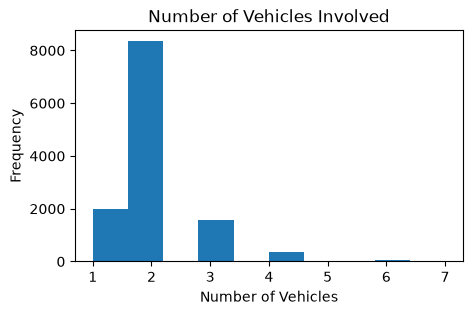

In [51]:
plt.figure(figsize=(5,3))

df['Number_of_vehicles_involved'].plot(kind='hist')
plt.title("Number of Vehicles Involved")
plt.xlabel("Number of Vehicles")
plt.ylabel("Frequency")
plt.show()

### INSIGHTS
+ Most accidents involve a small number of vehicles.
+ Accidents involving a larger number of vehicles occur less frequently.
+ This shows that multi-vehicle accidents are less common than accidents involving fewer vehicles.

#### 2.Number of Casualties

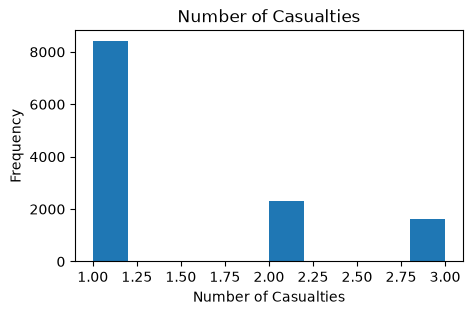

In [52]:
plt.figure(figsize=(5,3))

df['Number_of_casualties'].plot(kind='hist')
plt.title("Number of Casualties")
plt.xlabel("Number of Casualties")
plt.ylabel("Frequency")
plt.show()

### INSIGHTS
+ Most accidents have a small number of casualties.
+ Accidents with a higher number of casualties occur less frequently.
+ The distribution helps understand the severity of casualty occurrence.

### - Kde plot

#### 3.Distribution of City Development Index

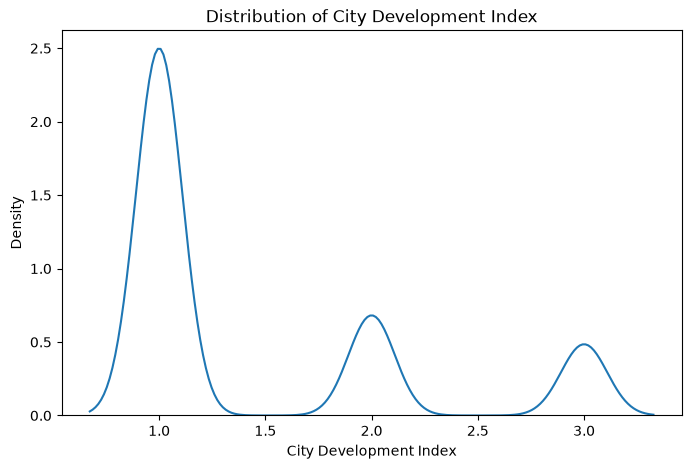

In [55]:
plt.figure(figsize=(8, 5))

sns.kdeplot(data=df, x='Number_of_casualties')
plt.title("Distribution of City Development Index")
plt.xlabel("City Development Index")
plt.ylabel("Density")
plt.show()

#### 9.2 Categorical columns

#### For Categorical columns use below graphs:   
+ Countplot
+ Barplot
+ Pie chart

### - Count plot

#### 1. Accident Severity

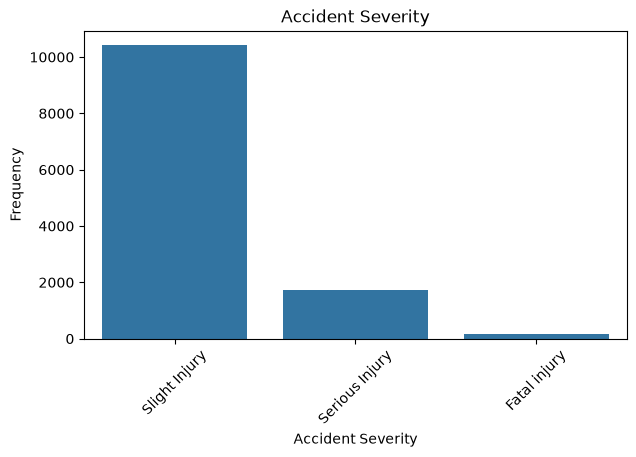

In [37]:
plt.figure(figsize=(7,4))

sns.countplot(data=df, x='Accident_severity')
plt.title("Accident Severity")
plt.xlabel("Accident Severity")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.show()

### INSIGHTS
+ The count plot shows the frequency of different accident severity levels.
+  Some severity categories occur more frequently than others.
+ This helps identify the most common accident severity in the dataset.

#### 2.Driving Experience

In [ ]:
plt.figure(figsize=(8,4))

sns.countplot(data=df, x='Driving_experience')
plt.title("Driving Experience")
plt.xlabel("Driving Experience")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.show()

### INSIGHTS
+ The graph shows the distribution of accidents across different driving experience groups.
+ Some experience groups have a higher number of accident records.
+ This helps understand how accident records are distributed according to driver experience.

In [ ]:
Road Surface Conditions

In [ ]:
plt.figure(figsize=(7,4))

sns.countplot(data=df, x='Road_surface_conditions')

plt.title("Road Surface Conditions")
plt.xlabel("Road Surface Conditions")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.show()

### INSIGHTS
+ The graph shows accidents under different road surface conditions.
+ Some road conditions occur more frequently in the dataset.
+ This helps identify the common road conditions associated with accidents.

#### 3.Weather Conditions

In [ ]:
plt.figure(figsize=(8,4))

sns.countplot(data=df, x='Weather_conditions')

plt.title("Weather Conditions")
plt.xlabel("Weather Conditions")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.show()

### INSIGHTS
+ The graph shows the distribution of accidents under different weather conditions.
+ Some weather conditions have considerably more accident records than others.
+ This helps understand the weather conditions commonly present during accidents.

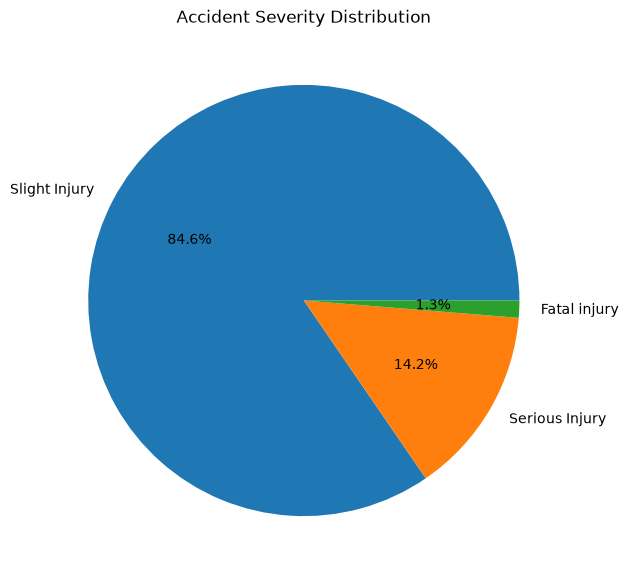

In [58]:
plt.figure(figsize=(7, 7))

df['Accident_severity'].value_counts().plot(kind='pie',autopct='%1.1f%%')
plt.title("Accident Severity Distribution")
plt.ylabel("")
plt.show()

### INSIGHTS
+ The pie chart shows the percentage distribution of accident severity.
+ The largest slice represents the most common accident severity.
+ It provides an easy view of the proportion of each severity category.

## 10. Bivariate Analysis 
+ Analysis can be done for two columns at a time.


### 10.1 Numerical × Numerical

#### For numerical columns use below graphs:   
+ Scatterplot

#### 1.Number of Vehicles vs Number of Casualties

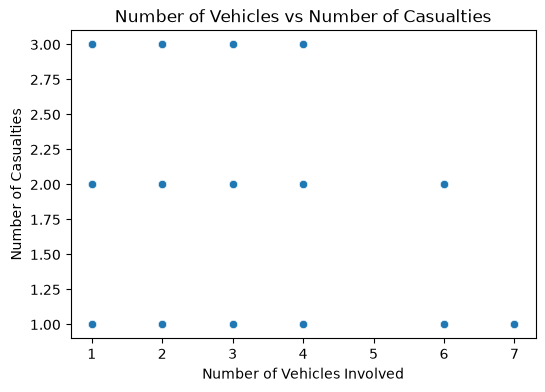

In [59]:
plt.figure(figsize=(6,4))

sns.scatterplot(data=df,x='Number_of_vehicles_involved',y='Number_of_casualties')
plt.xlabel("Number of Vehicles Involved")
plt.ylabel("Number of Casualties")
plt.title("Number of Vehicles vs Number of Casualties")
plt.show()

### INSIGHTS
+ The scatter plot shows the relationship between vehicles involved and casualties.
+ The points are distributed across different casualty levels.
+ It helps determine whether accidents involving more vehicles are associated with more casualties.

#### 10.2 Numerical × Categorical

#### For numerical and Categorical columns use below graphs:   
+ Boxplot
+ Barplot
+ Line Chart
+ Strip Plot
+ Swarm Plot
+ Violin Plot


### 1.Bar plot

#### Driving Experience × Average Casualties

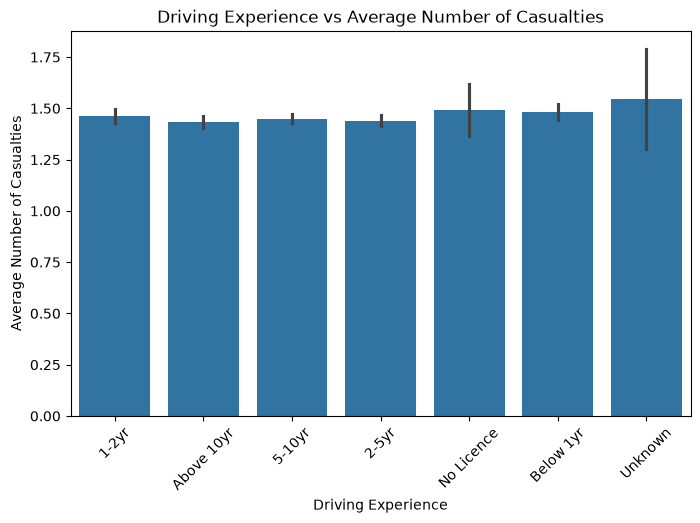

In [62]:
plt.figure(figsize=(8, 5))

sns.barplot(data=df,x="Driving_experience",y="Number_of_casualties")
plt.title("Driving Experience vs Average Number of Casualties")
plt.xlabel("Driving Experience")
plt.ylabel("Average Number of Casualties")
plt.xticks(rotation=45)
plt.show()

### Insight
+ The barplot compares the average number of casualties across driving-experience groups.
+ The average casualty count varies between experience categories.
+ It helps compare casualty levels for different driving-experience groups.

### 2.Line Chart

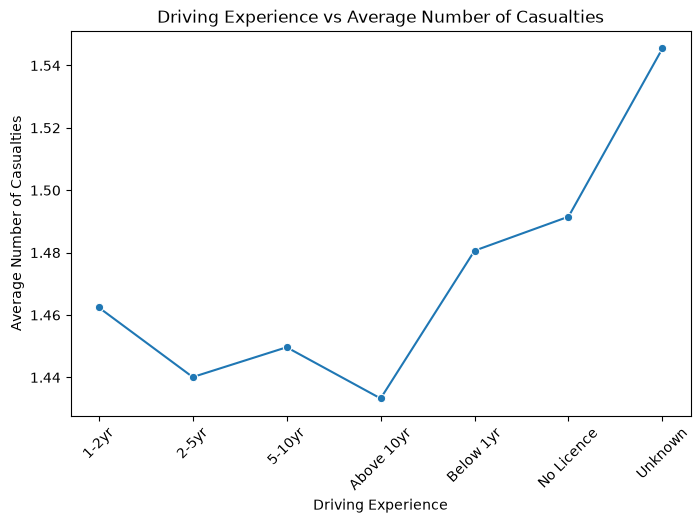

In [63]:
experience_casualties = df.groupby("Driving_experience")["Number_of_casualties"].mean().reset_index()
plt.figure(figsize=(8, 5))
sns.lineplot(
    data=experience_casualties,
    x="Driving_experience",
    y="Number_of_casualties",
    marker="o")
plt.title("Driving Experience vs Average Number of Casualties")
plt.xlabel("Driving Experience")
plt.ylabel("Average Number of Casualties")
plt.xticks(rotation=45)
plt.show()

### Insight
+ The line chart shows how the average number of casualties changes across driving-experience groups.
+ The values fluctuate between different experience categories.
+ It helps observe the pattern of average casualties across the categories.

### 3. Strip Plot

#### Accident Severity vs Number of Vehicles

In [39]:
cat

Index(['Time', 'Day_of_week', 'Age_band_of_driver', 'Sex_of_driver',
       'Educational_level', 'Vehicle_driver_relation', 'Driving_experience',
       'Type_of_vehicle', 'Owner_of_vehicle', 'Service_year_of_vehicle',
       'Defect_of_vehicle', 'Area_accident_occured', 'Lanes_or_Medians',
       'Road_allignment', 'Types_of_Junction', 'Road_surface_type',
       'Road_surface_conditions', 'Light_conditions', 'Weather_conditions',
       'Type_of_collision', 'Vehicle_movement', 'Casualty_class',
       'Sex_of_casualty', 'Age_band_of_casualty', 'Casualty_severity',
       'Work_of_casuality', 'Fitness_of_casuality', 'Pedestrian_movement',
       'Cause_of_accident', 'Accident_severity'],
      dtype='str')

### 3.Violin plot

#### 1.Day of weeks vs Number of Casualties

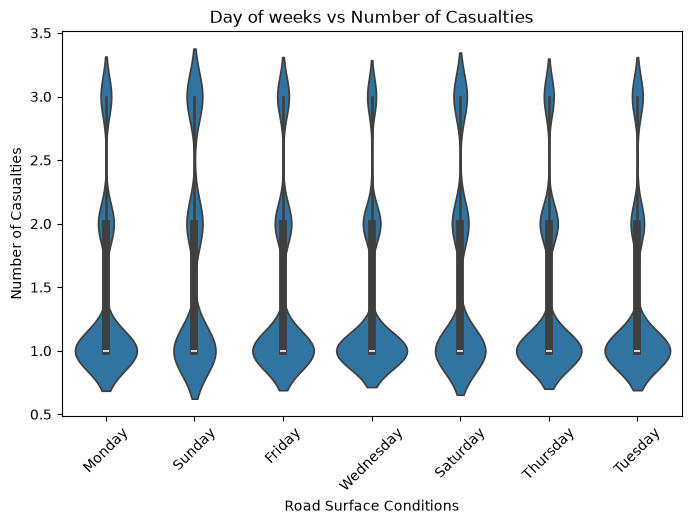

In [45]:
plt.figure(figsize=(8, 5))

sns.violinplot(data=df,x="Day_of_week",y="Number_of_casualties")
plt.title("Day of weeks vs Number of Casualties")
plt.xlabel("Road Surface Conditions")
plt.ylabel("Number of Casualties")
plt.xticks(rotation=45)
plt.show()

### Insights:
+ The violin plot shows the distribution of Number of Casualties across different days of the week.
+ Some days have a higher concentration of casualties, while others show a wider distribution.
+ The plot helps identify differences and variation in casualty counts across the days of the week.

#### 10.3  Categorical × Categorical

#### for Categorical and Categorical use below graphs:
+ Crosstab
+ Barplot

In [46]:
pd.crosstab(df["Day_of_week"],df["Accident_severity"])

Accident_severity,Fatal injury,Serious Injury,Slight Injury
Day_of_week,,,
Friday,16,313,1712
Monday,12,204,1465
Saturday,37,245,1384
Sunday,35,190,1242
Thursday,22,272,1557
Tuesday,17,257,1496
Wednesday,19,262,1559


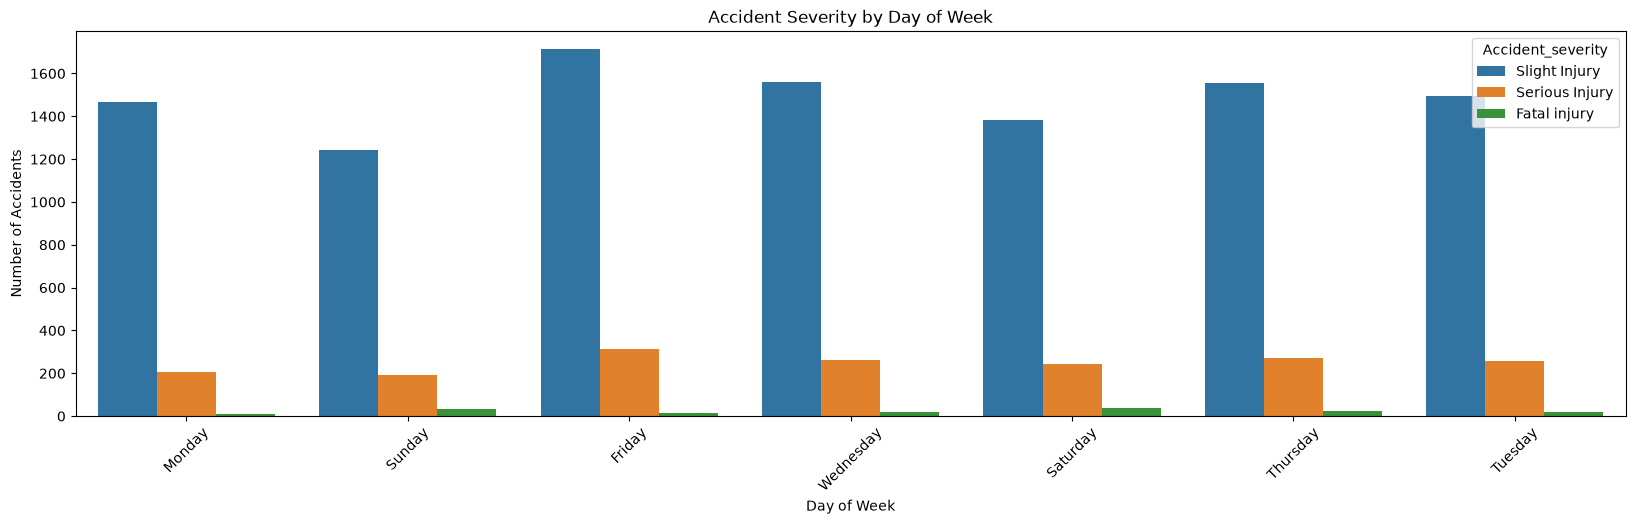

In [47]:
plt.figure(figsize=(20, 5))
sns.countplot(data=df, x="Day_of_week",hue="Accident_severity")
plt.title("Accident Severity by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Accidents")
plt.xticks(rotation=45)
plt.show()

### Insights:
+ The countplot shows the distribution of Accident Severity across different days of the week.
+ Slight injury accidents are the most frequent on most days compared to serious and fatal accidents.
+ The number of accidents varies by day, but Slight accidents consistently have the highest frequency.

## 11. Multivariate Analysis
+ Analysis can be done by more than 2 columns 
Use below graphs for Multivariate:
+ Heat map
+  Pair plot
+   Joint plot



#### 11.1 Heat map

In [48]:
df.corr(numeric_only=True)

,Number_of_vehicles_involved,Number_of_casualties
Number_of_vehicles_involved,1.000000,0.206632
Number_of_casualties,0.206632,1.000000


Text(0.5, 1.0, 'Correlation Heatmap')

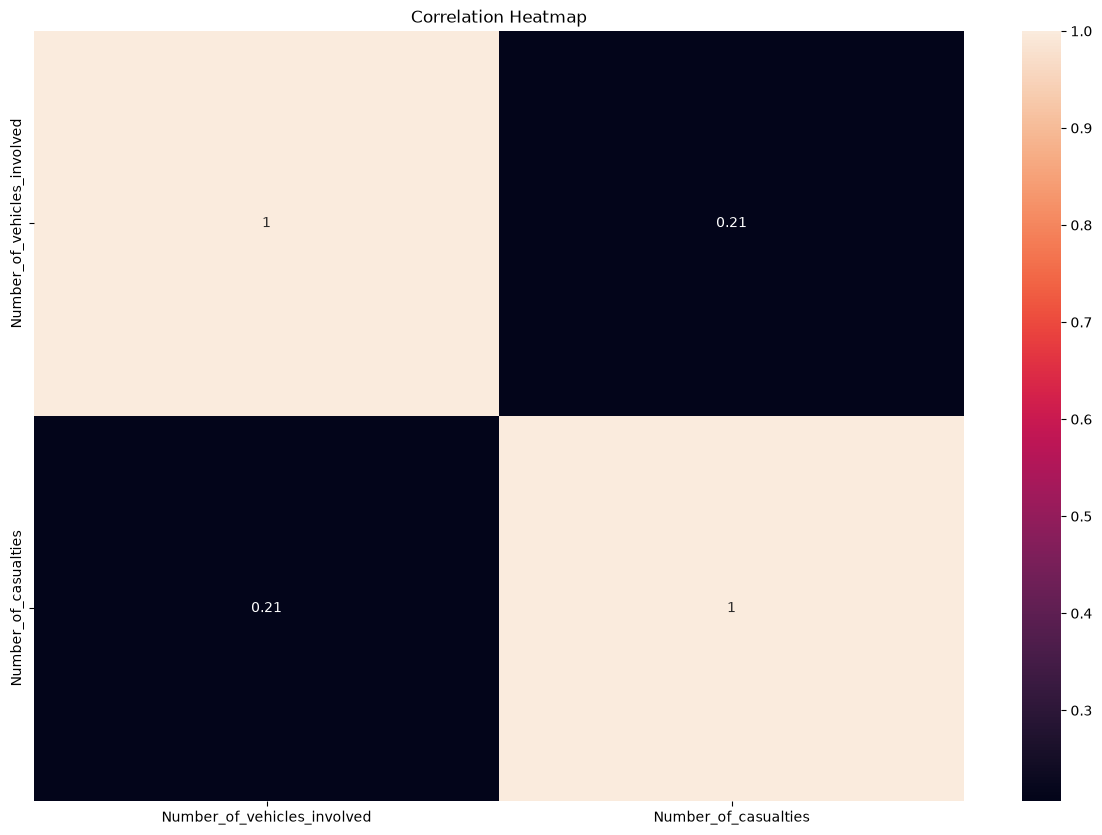

In [49]:
plt.figure(figsize = (15,10))
sns.heatmap(data = df.corr(numeric_only=True),annot= True)
plt.title("Correlation Heatmap")

#### Insights:
+ The heatmap shows the correlation between numerical variables in the dataset.
+ Number_of_vehicles_involved and Number_of_casualties show the relationship between the number of vehicles and casualties in an accident.
+ Overall, the heatmap helps identify positive, negative, and weak relationships between numerical variables.

#### 11.2 Pairplot

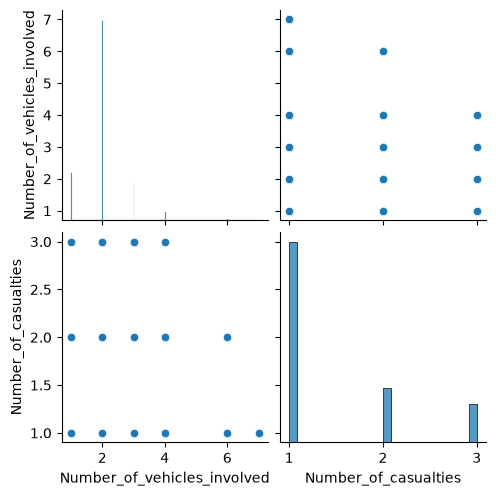

In [163]:
sns.pairplot(df[num])
plt.show()

#### Insights:
+ The pair plot shows the relationships and distributions between all numerical variables.
+ Number_of_vehicles_involved and Number_of_casualties show the relationship between the numerical variables.
+ The diagonal plots show the distribution of each numerical variable, while the scatter plots show their relationships.

#### 11.3 Joint plot

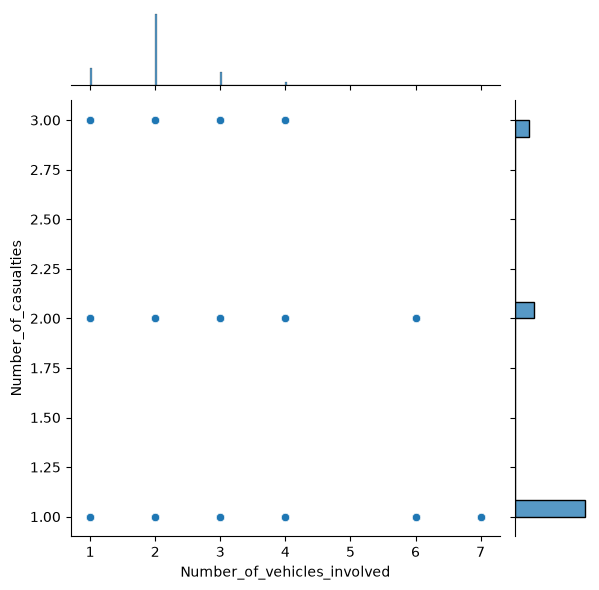

In [167]:
sns.jointplot(data=df,x="Number_of_vehicles_involved",y="Number_of_casualties")
plt.show()

#### Insights:
+ The joint plot shows the relationship between Number_of_vehicles_involved and Number_of_casualties.
+ It helps identify whether the number of casualties changes as the number of vehicles involved increases.
+ The plots on the sides show the individual distribution of vehicles involved and casualties.

## CONCLUSION:

### **What the data represents:**

+ This dataset represents road traffic accident information.
+ It contains information about accidents such as day, time, weather conditions, road conditions, vehicles involved, casualties, drivers, pedestrians, and accident severity.
+ The data helps us understand road accident patterns, accident severity, vehicle involvement, and factors associated with casualties.

### **What we have done:**

+ Checked the data types and structure.
+ Checked and handled missing values.
+ Checked and removed duplicate values.
+ Checked and corrected data inconsistencies.
+ Checked and treated outliers in numerical columns.
+ Performed data manipulation using Pandas.
+ Used `loc`, `iloc`, `at`, and `iat` for data selection.
+ Used Boolean masking, `query()`, `groupby()`, and `value_counts()`.
+ Used `pivot_table()` and `crosstab()` for data summarization.
+ Created new columns and performed data transformation.
+ Performed univariate analysis.
+ Performed bivariate analysis.
+ Performed multivariate analysis.
+ Used different charts to understand the accident data.
+ Created business questions and analyzed the data.
+ Identified useful patterns and relationships between accident-related variables.

### **Improvements / Applications:**

+ Identify factors associated with road accidents and casualties.
+ Understand accident patterns based on day, time, weather, and road conditions.
+ Identify accident severity patterns.
+ Understand the effect of vehicle involvement on casualties.
+ Analyze accident patterns across different vehicle types and driver characteristics.
+ Identify road and environmental conditions associated with more severe accidents.
+ Help organizations and authorities improve road safety measures.
+ Support better traffic management and accident prevention strategies.
+ Use accident data to support data-driven road safety decisions.

### **Final Conclusion:**

+ Overall, the analysis helped us understand road traffic accidents, accident severity, casualties, vehicle involvement, driver characteristics, weather conditions, and road conditions.
+ The analysis identified different patterns and relationships among accident-related factors.
+ The insights from this dataset can help in understanding accident-prone conditions, improving road safety, supporting traffic management, and developing better accident prevention strategies.